In [1]:
import sys,os
sys.path.append('../../')
import matplotlib.pyplot as plt
import numpy as np
from utils import makefolder

eps = 1E-7
rcpsize = 12
plt.rcParams['xtick.labelsize']= rcpsize
plt.rcParams['ytick.labelsize']=rcpsize
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = rcpsize
plt.rcParams.update({'figure.autolayout': True})
#colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['ggplot']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8-dark-palette']['axes.prop_cycle'].by_key()['color']
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)
# print(plt.rcParams.keys())
#np.set_printoptions(precision=None)
markers = ['*','p','o','h','^']
_linestyles = ['-','--','dotted']
plot_id = 0

layer_ids=array([ 0, 42, 60])


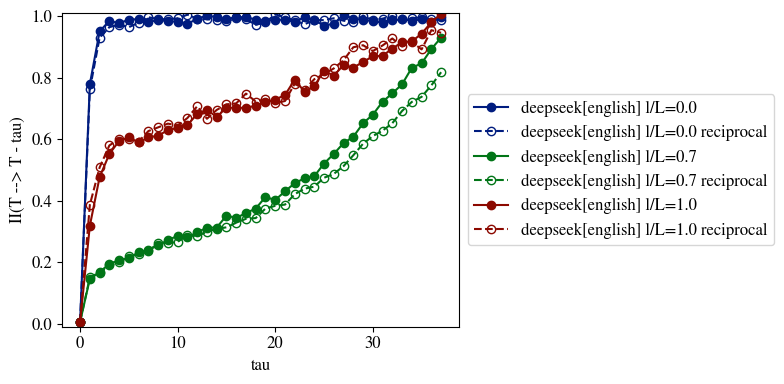

In [3]:
models = [
          # 'bert',
          'deepseek',
          # 'llama',
          ]
depths = {"deepseek":61,
          # "llama":32,
          # "bert":24,
          }
languages = [
            'english',
            # 'spanish',
            # 'german',
            # 'hungarian',
            # 'italian',
            ]
n_files = 400

mask = 2
min_token_lengths = [40]
k = 10
Nbits = 0
seed_list = np.arange(2,dtype=int) 
n_tokens = 1
take_last = 1
batch_shuffle = 0

figsfolder = f'results/figs/'
os.makedirs(figsfolder,exist_ok=True)
output_datafolder = f'{figsfolder}data/'
os.makedirs(output_datafolder,exist_ok=True)

fig,ax = plt.subplots(1,1,
                      figsize=(8,4),
                      # constrained_layout=True,
                      )
for min_token_length_id,min_token_length in enumerate(min_token_lengths):
  n_loaded_tokens = min_token_length - mask
  for model_id,model in enumerate(models):
    if model == 'deepseek': relative_depths = np.array([0.001,0.7,0.999])
    if model == 'llama': relative_depths = np.array([.001,.7,.999])
    if model == 'bert': relative_depths = np.array([.001,.5,.999])
    layer_ids = (relative_depths * depths[model]).astype(int)
    print(f'{layer_ids=}')
    for r_id,r in enumerate(relative_depths):
      for language_id, language in enumerate(languages):
          IIs = np.zeros(shape=(len(seed_list),2,depths[model],n_loaded_tokens))
          for seed_id,seed in enumerate(seed_list):
            II_folder = makefolder(base=f'./results/santiago/',
                                   subtract_mean=0,
                                   batch_shuffle=batch_shuffle,
                                      take_last=take_last,
                                      modelA=model,
                                      modelB=model,
                                      n_files=n_files,
                                      min_token_length=min_token_length,
                                      languageA=language,
                                      mask=mask,
                                      k=k,
                                      Nbits=Nbits,
                                      seed=seed,
                                      )
            IIs[seed_id,0] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_0_AB.npy')
            IIs[seed_id,1] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_0_BA.npy')
          ax.plot(range(0,n_loaded_tokens),
                    IIs[:,0,layer_ids[r_id],:].mean(axis=0),
                    linestyle=_linestyles[0],
                    label=f'{model}[{language}] l/L={round(relative_depths[r_id],1)}',
                    marker='o',
                    color=colors[r_id%len(colors)],)
          ax.plot(range(0,n_loaded_tokens),
                    IIs[:,1,layer_ids[r_id],:].mean(axis=0),
                    linestyle=_linestyles[1],
                    label=f'{model}[{language}] l/L={round(relative_depths[r_id],1)} reciprocal',
                    marker='o',
                    color=colors[r_id%len(colors)],
                    mfc='none',
                    )
          # np.savetxt(output_datafolder + f'{model}_{language}_layer{layer_ids[r_id]+1}_{min_token_length}_from_last.txt',
          #            IIs[:,0,layer_ids[r_id],:].mean(axis=0))
          # np.savetxt(output_datafolder + f'{model}_{language}_layer{layer_ids[r_id]+1}_{min_token_length}_to_last.txt',
          #            IIs[:,1,layer_ids[r_id],:].mean(axis=0))

# ax.set_xscale('log')
# ax.set_yscale('log')
ax.set_xlabel('tau')
ax.set_ylabel('II(T --> T - tau)')
ax.set_ylim(-0.01,1.01)
box = ax.get_position()
ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
fig.savefig(f'{figsfolder}_{model}_{layer_ids}_future-past-II.pdf',bbox_inches='tight')

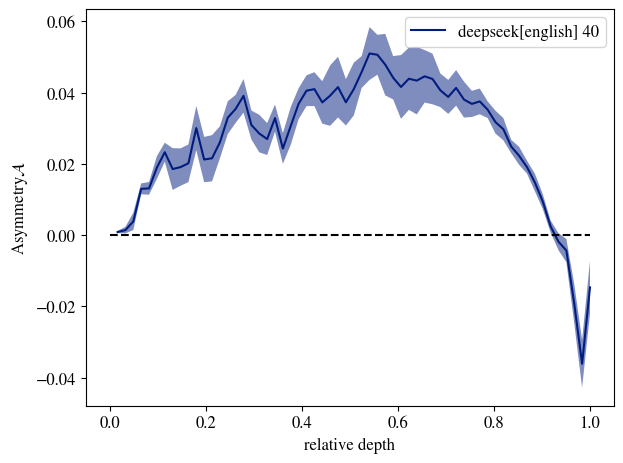

In [10]:
fig,ax = plt.subplots(1)

min_token_lengths = [40]
seed_list = np.arange(5,dtype=int)
for model_id,model in enumerate(models):
  for min_token_length_id,min_token_length in enumerate(min_token_lengths):
    n_loaded_tokens = min_token_length - mask
    for language_pair, language in enumerate(languages):
        IIs = np.zeros(shape=(len(seed_list),2,depths[model],n_loaded_tokens))
        for seed_id,seed in enumerate(seed_list):
          II_folder = makefolder(base=f'./results/santiago/',
                                 subtract_mean=0,
                                  batch_shuffle=batch_shuffle,
                                      take_last=take_last,
                                      modelA=model,
                                      modelB=model,
                                      n_files=n_files,
                                      min_token_length=min_token_length,
                                      languageA=language,
                                      mask=mask,
                                      k=k,
                                      Nbits=Nbits,
                                      seed=seed,
                                    )
          IIs[seed_id,0] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_0_AB.npy')
          IIs[seed_id,1] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_0_BA.npy')
        A = (IIs[:,0,:,:]- IIs[:,1,:,:]).mean(axis=-1)
        mu = A.mean(axis=0)
        std = A.std(axis=0)
        x = np.arange(1,depths[model]+1)/depths[model]
        ax.plot(x,
                  mu,
                  label=f'{model}[{language}] {min_token_length}',
                  )
        ax.fill_between(x,mu-std,mu+std,alpha=.5)
        # np.savetxt(f'{output_datafolder}asymmetry_layers_{model}_{language}_{min_token_length}.txt',
        # np.array([np.arange(1,depths[model]+1),A]).T)


ax.set_ylabel('Asymmetry' + r'$\mathcal{A}$')  
ax.set_xlabel('relative depth')
# ax.set_title(f'{min_token_length=}')

ax.hlines(0,0,1,color='black',linestyles='dashed')
ax.legend()
plt.show()

In [ ]:
    batch_shuffle = 1
